## Objectives

Lab 4 showed that feature scaling makes gradient descent hundreds of times faster. In this short lab you will see **why**:

- on a quadratic function whose curvature differs strongly between two directions, one learning rate cannot suit both directions;
- rescaling a variable turns the long, narrow contour ellipses into circles;
- exactly the same happens to the cost function of linear regression for two diabetes features.

## Tools

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes

np.set_printoptions(precision=3, suppress=True)   # print arrays with 3 decimals, no e-notation

## A quadratic with very different curvatures

Consider
$$
f(x_1, x_2) = 50\,x_1^2 + \tfrac12\,x_2^2 ,
$$
with its minimum at $(0, 0)$. Its contours are ellipses that are ten times longer in the $x_2$-direction than in the $x_1$-direction: $f$ is very steep in $x_1$ and very flat in $x_2$.

The gradient is $\nabla f = (100\,x_1,\ x_2)$, so one gradient-descent step $\mathbf x \leftarrow \mathbf x - \alpha\nabla f(\mathbf x)$ reads
$$
x_1 \leftarrow (1 - 100\,\alpha)\,x_1,
\qquad
x_2 \leftarrow (1 - \alpha)\,x_2 .
$$
Each coordinate behaves like the one-dimensional example $f(x) = (x-1)^2$ of the lecture, with curvature $\kappa_1 = \partial^2 f/\partial x_1^2 = 100$ and $\kappa_2 = \partial^2 f/\partial x_2^2 = 1$. Gradient descent converges only if $|1 - \kappa_j\alpha| < 1$ for **both** coordinates, i.e. $\alpha < 2/\kappa_1 = 0.02$. The steep direction sets the limit for $\alpha$.

In [2]:
def grad_f(x):
    """Gradient of f(x1, x2) = 50 x1^2 + 0.5 x2^2."""
    return np.array([100 * x[0], x[1]])

def gd_path(grad, x0, alpha, n_iters):
    """Gradient descent from x0; returns all iterates as an array of shape (n_iters+1, 2)."""
    path = np.zeros((n_iters + 1, 2))
    path[0] = x0
    for t in range(n_iters):
        path[t + 1] = path[t] - alpha * grad(path[t])
    return path

x0 = np.array([0.5, 5.0])

### A learning rate that suits $x_2$ diverges in $x_1$

For the flat direction $x_2$ alone, $\alpha = 0.5$ would be a good choice: $x_2$ halves at every step. But in the $x_1$-direction every step multiplies $x_1$ by $1 - 100 \cdot 0.5 = -49$:

In [3]:
print(gd_path(grad_f, x0, alpha=0.5, n_iters=3))

[[     0.5        5.   ]
 [   -24.5        2.5  ]
 [  1200.5        1.25 ]
 [-58824.5        0.625]]


### A learning rate that suits $x_1$ crawls in $x_2$

We therefore have to choose $\alpha < 0.02$; we take $\alpha = 0.019$. Now $x_1$ is multiplied by $1 - 1.9 = -0.9$ at each step (it oscillates, but shrinks), while $x_2$ is multiplied by $0.981$ only.

after 100 iterations: x1 = 1.3e-05, x2 = 0.734


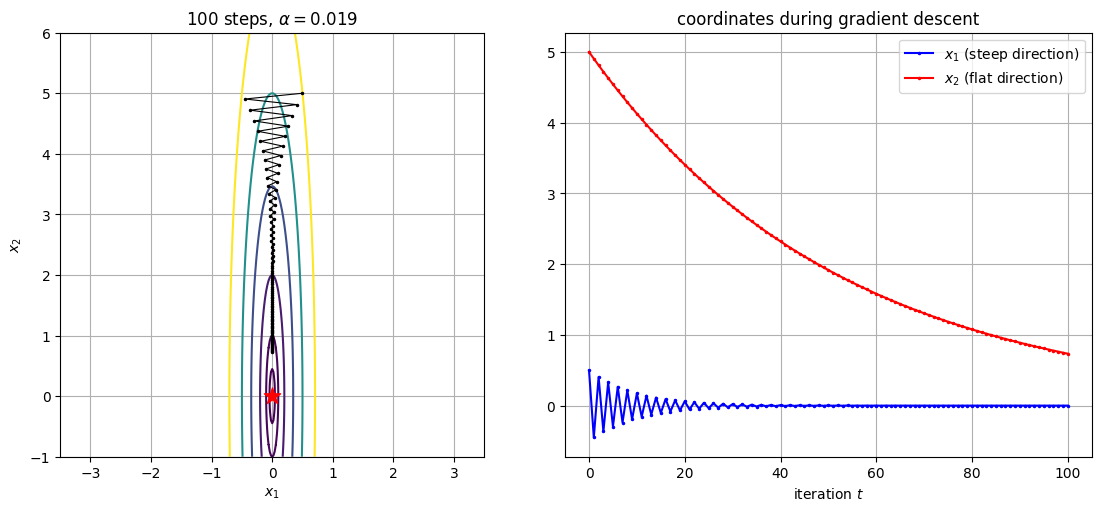

In [4]:
path = gd_path(grad_f, x0, alpha=0.019, n_iters=100)
print(f"after 100 iterations: x1 = {path[-1, 0]:.1e}, x2 = {path[-1, 1]:.3f}")

x1g, x2g = np.meshgrid(np.linspace(-3.5, 3.5, 351), np.linspace(-1, 6, 281))
f_grid = 50 * x1g**2 + 0.5 * x2g**2
levels = [0.1, 0.5, 2, 6, 12.5, 25]

fig, ax = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)
ax[0].contour(x1g, x2g, f_grid, levels=levels, cmap='viridis')
ax[0].plot(path[:, 0], path[:, 1], 'k.-', ms=3, lw=0.8)
ax[0].scatter(0, 0, marker='*', c='r', s=150, zorder=3)
ax[0].set(xlabel='$x_1$', ylabel='$x_2$', title='100 steps, $\\alpha = 0.019$', aspect='equal')
ax[1].plot(path[:, 0], 'b.-', ms=3, label='$x_1$ (steep direction)')
ax[1].plot(path[:, 1], 'r.-', ms=3, label='$x_2$ (flat direction)')
ax[1].set(xlabel='iteration $t$', title='coordinates during gradient descent')
ax[1].legend()
for a in ax:
    a.grid(True)
plt.show()

The iterates zigzag across the narrow valley while they crawl along it: after $100$ iterations, $x_1$ is essentially $0$, but $x_2$ has only come down from $5$ to about $0.7$. Since $\alpha < 0.02$, the factor for $x_2$ is always at least $0.98$, so reducing $x_2$ by a factor of $1000$ takes more than $340$ iterations, whatever $\alpha$ we choose.

## Rescaling the variable

Now measure $x_1$ in different units: let $u_1 = 10\,x_1$, i.e. $x_1 = u_1/10$. Then
$$
f = 50\,\Big(\frac{u_1}{10}\Big)^2 + \tfrac12\,x_2^2 = \tfrac12\,u_1^2 + \tfrac12\,x_2^2 .
$$
Both curvatures are now $1$: the contours are **circles**, the gradient points straight at the minimum, and any $\alpha < 2$ converges at the same rate in both directions. With $\alpha = 1$, gradient descent even reaches the minimum in a single step.

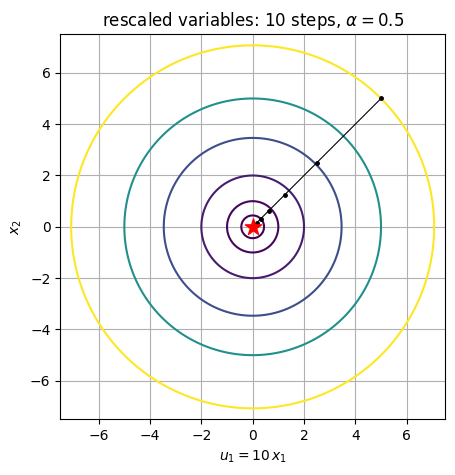

In [5]:
def grad_f_scaled(u):
    """Gradient of f = 0.5 u1^2 + 0.5 x2^2 in the rescaled variables (u1, x2)."""
    return np.array([u[0], u[1]])

u0 = np.array([10 * x0[0], x0[1]])          # the same starting point, in the new units
path_u = gd_path(grad_f_scaled, u0, alpha=0.5, n_iters=10)

ug1, ug2 = np.meshgrid(np.linspace(-7.5, 7.5, 151), np.linspace(-7.5, 7.5, 151))
plt.figure(figsize=(5, 5))
plt.contour(ug1, ug2, 0.5 * ug1**2 + 0.5 * ug2**2, levels=levels, cmap='viridis')
plt.plot(path_u[:, 0], path_u[:, 1], 'k.-', ms=5, lw=0.8)
plt.scatter(0, 0, marker='*', c='r', s=150, zorder=3)
plt.gca().set_aspect('equal')
plt.xlabel('$u_1 = 10\\,x_1$')
plt.ylabel('$x_2$')
plt.title('rescaled variables: 10 steps, $\\alpha = 0.5$')
plt.grid(True)
plt.show()

Rescaling the **variable** of a function is exactly what feature scaling does for linear regression, as we see next.

## The same picture for linear regression

We fit the diabetes data with two features, cholesterol S1 ($x_1$, values around 190) and BMI ($x_2$, values around 26):
$$
f_{\mathbf w,b}(\mathbf x) = w_1x_1 + w_2x_2 + b .
$$
The cost $J(w_1, w_2, b)$ depends on three parameters. To draw it in 2D, we keep $b$ at its best value for every $(w_1, w_2)$: from $\partial J/\partial b = 0$ we get $b = \bar y - w_1\mu_1 - w_2\mu_2$, and inserting this gives
$$
f_{\mathbf w,b}(\mathbf x^{(i)}) - y^{(i)} = w_1\big(x_1^{(i)} - \mu_1\big) + w_2\big(x_2^{(i)} - \mu_2\big) - \big(y^{(i)} - \bar y\big).
$$
So we work with **centred** features and target and only the two weights. For the scaled version we additionally divide each feature by its standard deviation $\sigma_j$ (z-score normalisation).

In [6]:
diabetes = load_diabetes(scaled=False)
names = diabetes.feature_names
X = diabetes.data[:, [names.index('s1'), names.index('bmi')]]
y = diabetes.target

mu, sigma = X.mean(axis=0), X.std(axis=0)
y_c = y - y.mean()
X_raw = X - mu                  # centred, raw units
X_scaled = (X - mu) / sigma     # centred and scaled (z-score)

def cost(Z, w):
    """J(w1, w2) with b at its best value (centred features Z and target y_c)."""
    return np.mean((Z @ w - y_c) ** 2) / 2

def gd_weights(Z, alpha, n_iters):
    """Gradient descent on (w1, w2) from (0, 0); returns all iterates."""
    return gd_path(lambda w: Z.T @ (Z @ w - y_c) / len(y_c), np.zeros(2), alpha, n_iters)

We run $25$ steps of gradient descent in both cases: with $\alpha = 0.0015$ for the raw features, just below their stability limit of about $0.0017$, and with $\alpha = 0.8$ for the scaled features, whose limit is about $1.6$.

raw features            : after 25 steps w = [0.318 4.974], minimum at [0.156 9.928]


z-score scaled features : after 25 steps w = [ 5.383 43.816], minimum at [ 5.383 43.816]


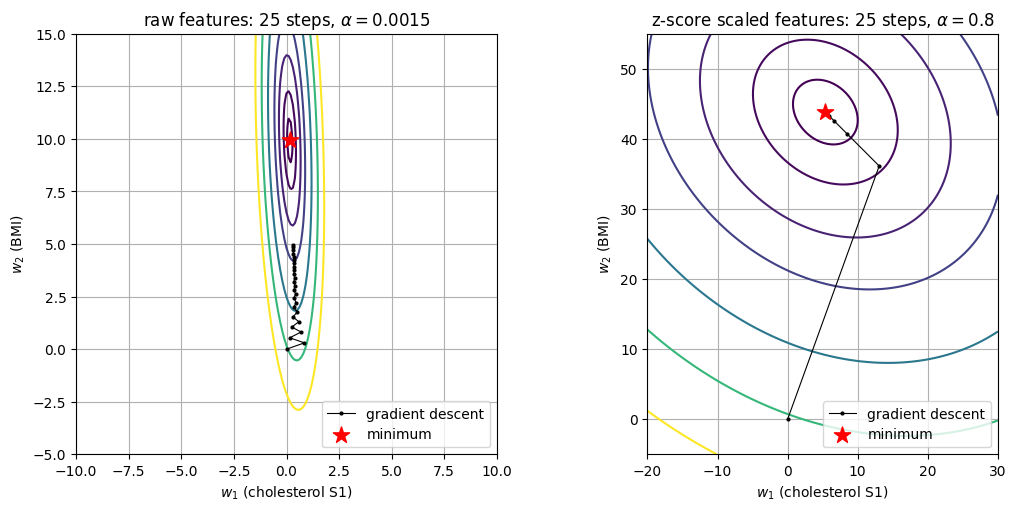

In [7]:
setups = [("raw features", X_raw, 0.0015, (-10, 10), (-5, 15)),
          ("z-score scaled features", X_scaled, 0.8, (-20, 30), (-5, 55))]

fig, ax = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)
for a, (title, Z, alpha, w1_lim, w2_lim) in zip(ax, setups):
    W1, W2 = np.meshgrid(np.linspace(*w1_lim, 201), np.linspace(*w2_lim, 201))
    J_grid = np.zeros_like(W1)
    for i in range(W1.shape[0]):
        for j in range(W1.shape[1]):
            J_grid[i, j] = cost(Z, np.array([W1[i, j], W2[i, j]]))
    w_best = np.linalg.solve(Z.T @ Z, Z.T @ y_c)          # normal equation (Lab 5)
    J_best = cost(Z, w_best)
    path = gd_weights(Z, alpha, 25)

    a.contour(W1, W2, J_grid, levels=J_best + np.array([10, 50, 150, 300, 600, 1000, 1500]),
              cmap='viridis')
    a.plot(path[:, 0], path[:, 1], 'k.-', ms=4, lw=0.8, label='gradient descent')
    a.scatter(*w_best, marker='*', c='r', s=150, zorder=3, label='minimum')
    a.set(xlabel='$w_1$ (cholesterol S1)', ylabel='$w_2$ (BMI)',
          title=f'{title}: 25 steps, $\\alpha = {alpha}$', aspect='equal')
    a.legend(loc='lower right')
    a.grid(True)
    print(f"{title:24s}: after 25 steps w = {path[-1].round(3)}, minimum at {w_best.round(3)}")
plt.show()

- **Raw features:** S1 varies about eight times more than BMI ($\sigma_1 \approx 34.6$, $\sigma_2 \approx 4.4$), so $J$ is about $60$ times more sensitive to $w_1$ than to $w_2$. The contours are long, narrow ellipses, $\alpha$ is limited by the steep $w_1$-direction, and after $25$ steps $w_2$ is only halfway to its optimal value.
- **Scaled features:** both features vary equally, the contours are almost circles, and gradient descent reaches the minimum within $25$ steps. The ellipses are slightly tilted because S1 and BMI are correlated; scaling cannot remove that.

With all ten features, the cost lives in eleven dimensions and cannot be drawn, but the mechanism is the same: this is why scaling sped up gradient descent so dramatically in Lab 4.

## Challenges

1. For $f(x_1, x_2) = 50x_1^2 + \frac12 x_2^2$, which $\alpha$ makes the slower of the two factors $|1 - 100\alpha|$ and $|1 - \alpha|$ as small as possible? How many iterations does gradient descent then need to reduce both coordinates by a factor of $1000$? (*Hint:* the best $\alpha$ makes both factors equal.)
2. Repeat the diabetes experiment with min-max scaling instead of z-score scaling. Are the contours still close to circles?

## Summary

- Gradient descent uses one learning rate for all directions. The steepest direction limits $\alpha$, and then the flattest direction converges slowly.
- How steep $J$ is in the direction of $w_j$ depends on how much feature $x_j$ varies: features on very different scales give long, narrow valleys.
- Feature scaling is a change of units that makes all directions similarly steep: the contours become (nearly) circles and gradient descent heads straight for the minimum.